In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/Unicorn_Companies.csv")
print("Shape:", df.shape)
df.head()

Shape: (1037, 13)


,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0
1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
4,Epic Games,$42,10/26/2018,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0


In [2]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values:")
missing = df.isnull().sum()
print(pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037 entries, 0 to 1036
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Company            1037 non-null   object 
 1   Valuation ($B)     1037 non-null   object 
 2   Date Joined        1037 non-null   object 
 3   Country            1037 non-null   object 
 4   City               1037 non-null   object 
 5   Industry           1037 non-null   object 
 6   Select Inverstors  1020 non-null   object 
 7   Founded Year       994 non-null    float64
 8   Total Raised       1013 non-null   object 
 9   Financial Stage    49 non-null     object 
 10  Investors Count    1036 non-null   float64
 11  Deal Terms         1008 non-null   float64
 12  Portfolio Exits    49 non-null     float64
dtypes: float64(4), object(9)
memory usage: 105.4+ KB

Duplicate rows: 0

Missing values:
                   missing  percent
Company                  0     0.00
Valuation (

In [3]:
print(df["Financial Stage"].value_counts(dropna=False))
print()
print(df[["Valuation ($B)", "Total Raised"]].sample(8, random_state=1))
print()
print(df["Industry"].value_counts())

Financial Stage
NaN            988
Acquired        22
Divestiture      8
IPO              7
Acq              7
Asset            1
Take             1
Management       1
Reverse          1
Corporate        1
Name: count, dtype: int64

    Valuation ($B) Total Raised
589          $1.43        $143M
718           $1.2     $472.94M
677          $1.22     $911.62M
956             $1          NaN
314           $2.6     $708.73M
345           $2.4     $711.73M
99            $6.1        $645M
649           $1.3        $290M

Industry
Fintech                                                               205
Internet software & services                                          192
E-commerce & direct-to-consumer                                       107
Artificial intelligence                                                71
Health                                                                 69
Supply chain, logistics, & delivery                                    57
Other                    

In [4]:
ind = df["Industry"].value_counts()
print(ind.head(20))
print("\nDistinct Industry values:", len(ind))
print("Values appearing only once:", (ind == 1).sum())
print()
print(df[df["Industry"].isin(ind[ind == 1].index)].head(5).T)


Industry
Fintech                                                               205
Internet software & services                                          192
E-commerce & direct-to-consumer                                       107
Artificial intelligence                                                71
Health                                                                 69
Supply chain, logistics, & delivery                                    57
Other                                                                  56
Cybersecurity                                                          49
Data management & analytics                                            41
Mobile & telecommunications                                            37
Hardware                                                               33
Auto & transportation                                                  29
Edtech                                                                 28
Consumer & retail            

In [5]:
valid = ["Fintech", "Internet software & services", "E-commerce & direct-to-consumer",
         "Artificial intelligence", "Artificial Intelligence", "Health",
         "Supply chain, logistics, & delivery", "Other", "Cybersecurity",
         "Data management & analytics", "Mobile & telecommunications", "Hardware",
         "Auto & transportation", "Edtech", "Consumer & retail", "Travel", "Finttech"]
bad = df[~df["Industry"].isin(valid)]
print("Bad rows:", len(bad))
bad[["Company", "Valuation ($B)", "Country", "City", "Industry"]]

Bad rows: 16


,Company,Valuation ($B),Country,City,Industry
10,FTX,$32,Bahamas,Fintech,"Sequoia Capital, Thoma Bravo, Softbank"
217,HyalRoute,$3.5,Singapore,Mobile & telecommunications,Kuang-Chi
292,Amber Group,$3,Hong Kong,Fintech,"Tiger Global Management, Tiger Brokers, DCM Ve..."
318,Moglix,$2.6,Singapore,E-commerce & direct-to-consumer,"Jungle Ventures, Accel, Venture Highway"
438,Advance Intelligence Group,$2,Singapore,Artificial intelligence,"Vision Plus Capital, GSR Ventures, ZhenFund"
639,Trax,$1.3,Singapore,Artificial intelligence,"Hopu Investment Management, Boyu Capital, DC T..."
757,Carousell,$1.1,Singapore,E-commerce & direct-to-consumer,"500 Global, Rakuten Ventures, Golden Gate Vent..."
814,WeLab,$1,Hong Kong,Fintech,"Sequoia Capital China, ING, Alibaba Entreprene..."
882,PatSnap,$1,Singapore,Internet software & services,"Sequoia Capital China, Shunwei Capital Partner..."
911,Matrixport,$1.05,Singapore,Fintech,"Dragonfly Captial, Qiming Venture Partners, DS..."


In [6]:
print("Bad rows:", len(bad))
bad.head(3).T

Bad rows: 16


,10,217,292
Company,FTX,HyalRoute,Amber Group
Valuation ($B),$32,$3.5,$3
Date Joined,7/20/2021,5/26/2020,6/21/2021
Country,Bahamas,Singapore,Hong Kong
City,Fintech,Mobile & telecommunications,Fintech
Industry,"Sequoia Capital, Thoma Bravo, Softbank",Kuang-Chi,"Tiger Global Management, Tiger Brokers, DCM Ve..."
Select Inverstors,NaN,NaN,NaN
Founded Year,2018.0,2015.0,2015.0
Total Raised,$1.829B,$263.12M,$328M
Financial Stage,Acq,NaN,NaN


In [7]:
df = df.copy()
mask = ~df["Industry"].isin(valid)

df.loc[mask, "Select Inverstors"] = df.loc[mask, "Industry"]
df.loc[mask, "Industry"] = df.loc[mask, "City"]
df.loc[mask, "City"] = np.where(
    df.loc[mask, "Country"].isin(["Singapore", "Hong Kong"]),
    df.loc[mask, "Country"],
    np.nan,
)

# merge spelling variants
df["Industry"] = df["Industry"].replace({
    "Artificial Intelligence": "Artificial intelligence",
    "Finttech": "Fintech",
})

print("Distinct industries:", df["Industry"].nunique())
print(df["Industry"].value_counts())
df.loc[mask, ["Company", "Country", "City", "Industry", "Select Inverstors"]]

Distinct industries: 15
Industry
Fintech                                212
Internet software & services           194
E-commerce & direct-to-consumer        111
Artificial intelligence                 80
Health                                  69
Supply chain, logistics, & delivery     58
Other                                   56
Cybersecurity                           49
Data management & analytics             41
Mobile & telecommunications             38
Hardware                                33
Auto & transportation                   29
Edtech                                  28
Consumer & retail                       25
Travel                                  14
Name: count, dtype: int64


,Company,Country,City,Industry,Select Inverstors
10,FTX,Bahamas,NaN,Fintech,"Sequoia Capital, Thoma Bravo, Softbank"
217,HyalRoute,Singapore,Singapore,Mobile & telecommunications,Kuang-Chi
292,Amber Group,Hong Kong,Hong Kong,Fintech,"Tiger Global Management, Tiger Brokers, DCM Ve..."
318,Moglix,Singapore,Singapore,E-commerce & direct-to-consumer,"Jungle Ventures, Accel, Venture Highway"
438,Advance Intelligence Group,Singapore,Singapore,Artificial intelligence,"Vision Plus Capital, GSR Ventures, ZhenFund"
639,Trax,Singapore,Singapore,Artificial intelligence,"Hopu Investment Management, Boyu Capital, DC T..."
757,Carousell,Singapore,Singapore,E-commerce & direct-to-consumer,"500 Global, Rakuten Ventures, Golden Gate Vent..."
814,WeLab,Hong Kong,Hong Kong,Fintech,"Sequoia Capital China, ING, Alibaba Entreprene..."
882,PatSnap,Singapore,Singapore,Internet software & services,"Sequoia Capital China, Shunwei Capital Partner..."
911,Matrixport,Singapore,Singapore,Fintech,"Dragonfly Captial, Qiming Venture Partners, DS..."


In [8]:
# 1. Valuation: "$140" -> 140.0 (billions)
df["Valuation"] = df["Valuation ($B)"].str.replace("[$,]", "", regex=True).astype(float)

# 2. Total Raised: "$143M" / "$1.829B" -> millions
def to_millions(x):
    if pd.isna(x):
        return np.nan
    x = str(x).replace("$", "").replace(",", "").strip()
    if x.endswith("B"):
        return float(x[:-1]) * 1000
    if x.endswith("M"):
        return float(x[:-1])
    if x.endswith("K"):
        return float(x[:-1]) / 1000
    try:
        return float(x)
    except ValueError:
        return np.nan

df["Total Raised (M)"] = df["Total Raised"].apply(to_millions)

# 3. Dates and founding year
df["Date Joined"] = pd.to_datetime(df["Date Joined"], errors="coerce")
df["Join Year"] = df["Date Joined"].dt.year
df["Founded Year"] = df["Founded Year"].astype("Int64")
df["Years to Unicorn"] = df["Join Year"] - df["Founded Year"]

# 4. Target: exited (any Financial Stage value) vs still private
df["Exited"] = df["Financial Stage"].notna().astype(int)

# 5. Quick checks
print("Valuation nulls:", df["Valuation"].isna().sum())
print("Total Raised nulls:", df["Total Raised (M)"].isna().sum())
print("Date nulls:", df["Date Joined"].isna().sum())
print("Exited counts:\n", df["Exited"].value_counts())
print("Unparsed Total Raised:", df.loc[df["Total Raised (M)"].isna() & df["Total Raised"].notna(), "Total Raised"].unique())
print()
print(df[["Valuation", "Total Raised (M)", "Years to Unicorn"]].describe().round(2))


Valuation nulls: 0
Total Raised nulls: 24
Date nulls: 0
Exited counts:
 Exited
0    988
1     49
Name: count, dtype: int64
Unparsed Total Raised: []

       Valuation  Total Raised (M)  Years to Unicorn
count    1037.00           1013.00             994.0
mean        3.29            575.77              7.12
std         7.31            736.09              5.54
min         1.00              0.01              -4.0
25%         1.08            227.34               4.0
50%         1.60            377.70               6.0
75%         3.10            633.78               9.0
max       140.00           7440.00              98.0


In [9]:
odd = df[(df["Years to Unicorn"] < 0) | (df["Years to Unicorn"] > 40)]
print("Suspicious rows:", len(odd))
odd[["Company", "Founded Year", "Join Year", "Years to Unicorn", "Country"]].sort_values("Years to Unicorn")


Suspicious rows: 2


,Company,Founded Year,Join Year,Years to Unicorn,Country
599,Yidian Zixun,2021,2017,-4,China
215,Otto Bock HealthCare,1919,2017,98,Germany


In [10]:
# Impossible: founded after joining -> set founding info to missing
bad_year = df["Years to Unicorn"] < 0
df.loc[bad_year, ["Founded Year", "Years to Unicorn"]] = pd.NA

# Tidy column names for later notebooks
df = df.rename(columns={"Select Inverstors": "Select Investors"})

# Save
df.to_csv("../data/Unicorn_Companies_cleaned.csv", index=False)
print("Saved:", df.shape)
print("Years to Unicorn range:", df["Years to Unicorn"].min(), "to", df["Years to Unicorn"].max())


Saved: (1037, 18)
Years to Unicorn range: 0 to 98


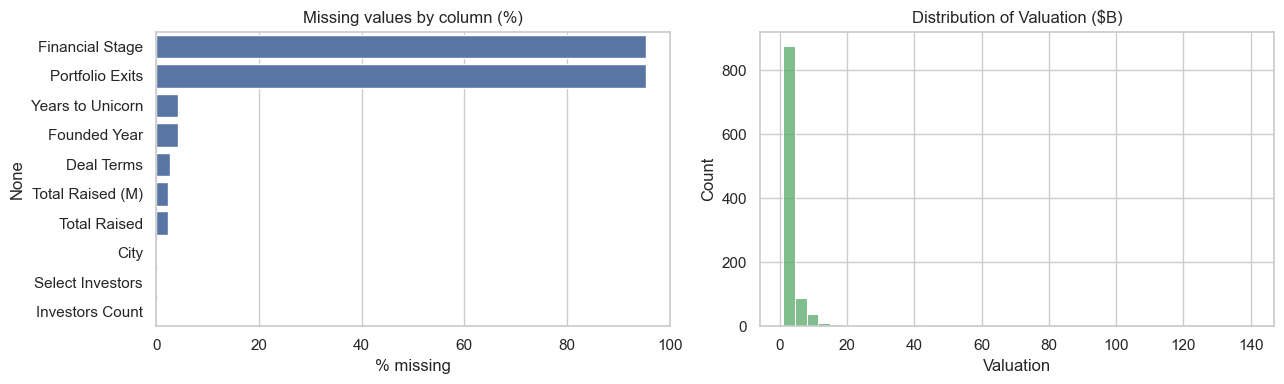

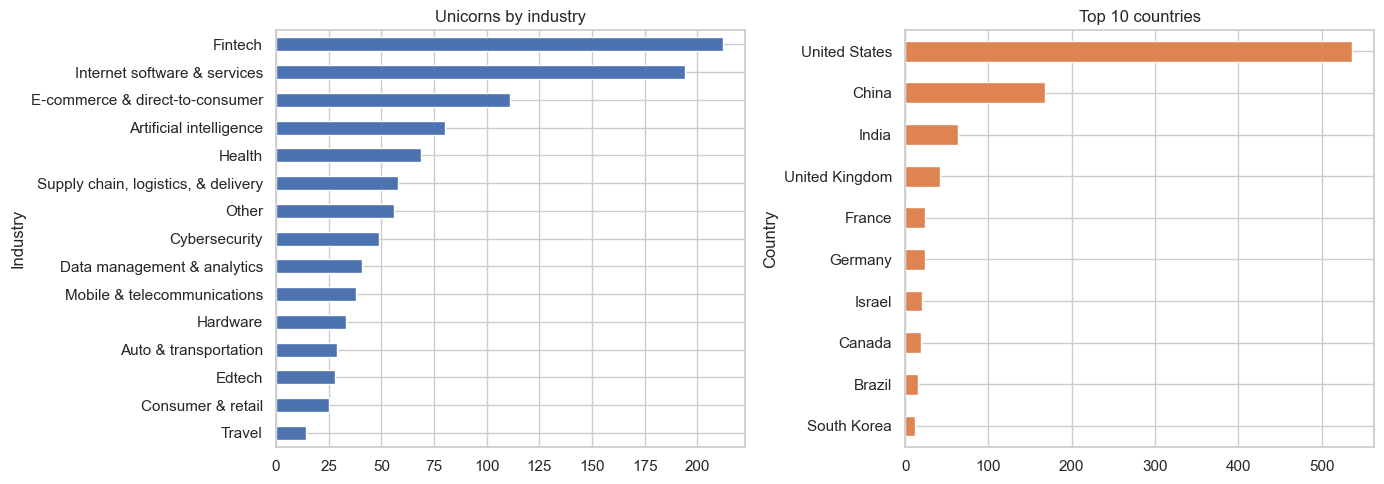

In [11]:
import os
os.makedirs("../results/plots", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Missing values (cleaned data)
miss = (df.isnull().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
sns.barplot(x=miss.values, y=miss.index, ax=axes[0], color="#4C72B0")
axes[0].set_title("Missing values by column (%)")
axes[0].set_xlabel("% missing")

# Valuation distribution: raw vs log
sns.histplot(df["Valuation"], bins=40, ax=axes[1], color="#55A868")
axes[1].set_title("Distribution of Valuation ($B)")
plt.tight_layout()
plt.savefig("../results/plots/01_missing_and_valuation.png", dpi=150)
plt.show()

# Industry and country counts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["Industry"].value_counts().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Unicorns by industry")
axes[0].invert_yaxis()
df["Country"].value_counts().head(10).plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("Top 10 countries")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig("../results/plots/01_industry_country.png", dpi=150)
plt.show()

In [12]:
print("Companies:", len(df))
print("Median valuation: $%.2fB | Mean: $%.2fB" % (df["Valuation"].median(), df["Valuation"].mean()))
print("Top industry:", df["Industry"].value_counts().idxmax())
print("Top country:", df["Country"].value_counts().idxmax(),
      "(%.1f%%)" % (df["Country"].value_counts(normalize=True).max() * 100))
print("Exited (IPO/acquired/etc.): %d (%.1f%%)" % (df["Exited"].sum(), df["Exited"].mean() * 100))
print("Median years to unicorn:", df["Years to Unicorn"].median())

Companies: 1037
Median valuation: $1.60B | Mean: $3.29B
Top industry: Fintech
Top country: United States (51.7%)
Exited (IPO/acquired/etc.): 49 (4.7%)
Median years to unicorn: 6.0
